Seminario de Actualización · Tecnicatura Superior en Ciencia de Datos e IA · IFTS N.º 18
Docente: Cynthia M. Villagra · Ciclo lectivo 2026 · Segundo cuatrimestre

**BORRADOR — para revisión de contenido**

# Del dataset al modelo exportado

## El camino del entrenamiento, con regresión lineal en scikit-learn, PyTorch y Keras

Al final de este notebook vas a tener un modelo que predice el precio de una casa, guardado en un archivo que se puede usar en otra app sin volver a entrenar. En el camino vas a ver qué hace `fit` por dentro.

**Cómo se usa**

- Ejecutá las celdas **de a una**, en orden.
- **PREDICCIÓN**: escribí tu respuesta en la celda de texto **antes** de ejecutar la celda de código que sigue. No importa si no acertás.
- **ERROR INTENCIONAL**: el error es a propósito. Leé el mensaje antes de seguir.
- Los términos nuevos aparecen en **negrita** la primera vez que se usan. Están todos juntos en el glosario del final.

In [ ]:
%pip install -q skops skl2onnx onnx onnxscript onnxruntime

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

## 1. El problema

Tenemos 200 casas con su precio, en miles de US$.

In [2]:
# default_rng() es el nuevo generador de números aleatorio
# 42 es el número de semilla, asegura reproducibilidad
rng = np.random.default_rng(42)

# n la cantidad de casas
n = 200

# rng genera de manera aleatoria una tupla con los m2
# de 200 casas
m2 = rng.integers(35, 121, n)

# Valores entre 0 y 1 si la casa tiene balcon
balcon = rng.integers(0, 2, n)

# Lo mismo si presenta ascensor
ascensor = rng.integers(0, 2, n)

# La formula para GENERAR el precio de la casa
# (no estimar, ya que es lo que haremos al entrenar
# el modelo de regresión)
# rng.normal() genera valores que sigan una distribución normal o gaussiana
precio = 1.5 * m2 + 8 * balcon + 12 * ascensor + 20 + rng.normal(0, 4, n)

# (Ojo que 1.5, 8, 12, 20 y el valor restante son tantos los pesos como el bias
# que es lo que el modelo estimará a la hora de ser entrenado. Aca se fijan
# de manera predeterminada por que el dataset es aleatorio)

# Se crea el dataframa con todos los datos generados
casas = pd.DataFrame({"m2": m2, "balcon": balcon, "ascensor": ascensor, "precio": precio.round(1)})
casas.head(8)

,m2,balcon,ascensor,precio
0,42,0,1,93.8
1,101,1,1,191.1
2,91,0,0,155.5
3,72,1,1,148.6
4,72,0,0,133.9
5,108,0,1,183.7
6,42,1,0,90.1
7,94,1,0,169.7


`balcon` y `ascensor` valen 1 si la casa lo tiene y 0 si no.

Llega una casa nueva: **65 m², con balcón, sin ascensor**. No tiene precio. ¿Cuánto vale?

Para responderlo necesitamos una fórmula que, a partir de los m², el balcón y el ascensor, devuelva un precio. Si suponemos que cada característica suma una cantidad fija, la fórmula tiene esta forma:

  precio = **w1** · m2 + **w2** · balcon + **w3** · ascensor + **b**

- `m2`, `balcon` y `ascensor` son las **características** (o entradas): las llamamos x1, x2, x3.
- `precio` es la **etiqueta** (o salida): la llamamos y.
- w1, w2, w3 son los **pesos**: cuánto suma cada característica.
- b es el **bias**: el precio base, cuando todas las x valen 0.

Entrenar es encontrar los números w1, w2, w3 y b que mejor reproducen los precios de la tabla.

**PREDICCIÓN 1.** Antes de entrenar nada, vamos a estimar los pesos mirando los datos. Un peso dice **cuánto cambia el precio cuando cambia una característica y las demás quedan iguales**. Los precios tienen una parte al azar, así que no va a dar exacto: buscamos un valor aproximado.

**w1: cuánto suma cada m²**

Cada punto del gráfico es una casa.

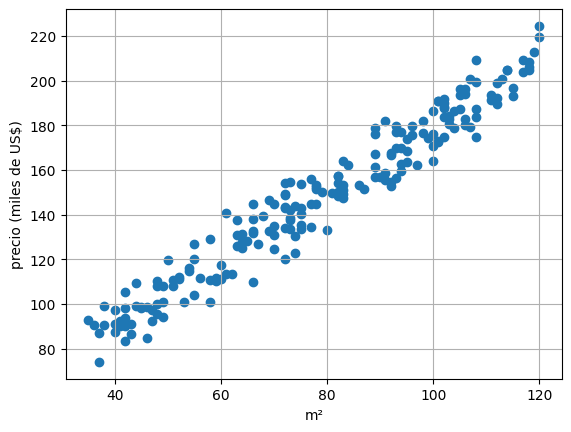

In [3]:
plt.scatter(casas["m2"], casas["precio"])
plt.xlabel("m²")
plt.ylabel("precio (miles de US$)")
plt.grid(True)
plt.show()

Mirá el gráfico: cuando los m² pasan de 50 a 100, ¿cuánto sube el precio, más o menos? Dividí esa subida por 50. Eso es lo que suma cada m², en miles de US$.

*Tu estimación:*

- subida del precio entre 50 y 100 m²: $70$
- w1 (subida / 50): $1.4$

**w2: cuánto suma tener balcón**

Para ver solo el efecto del balcón, comparamos casas parecidas en lo demás: todas tienen entre 60 y 70 m² y ninguna tiene ascensor. Lo único que cambia es el balcón.

In [4]:
parecidas = casas[casas["m2"].between(60, 70) & (casas["ascensor"] == 0)]
display(parecidas.sort_values("balcon"))
print("Promedios según balcón:")
print(parecidas.groupby("balcon")[["m2", "precio"]].mean().round(1))

,m2,balcon,ascensor,precio
52,66,0,0,109.8
153,60,0,0,111.3
162,70,0,0,124.5
166,62,0,0,113.3
135,61,1,0,113.6
64,70,1,0,130.7
143,70,1,0,134.9
43,65,1,0,128.1
163,69,1,0,132.9
187,67,1,0,127.1


Promedios según balcón:
          m2  precio
balcon              
0       64.5   114.7
1       67.0   127.9


¿Cuánto más cuestan, en promedio, las que tienen balcón?

*Tu estimación:*

- w2: $13,2$

**w3: cuánto suma tener ascensor**

Lo mismo, ahora con casas de entre 60 y 70 m² sin balcón. Lo único que cambia es el ascensor.

In [5]:
parecidas = casas[casas["m2"].between(60, 70) & (casas["balcon"] == 0)]
display(parecidas.sort_values("ascensor"))
print("Promedios según ascensor:")
print(parecidas.groupby("ascensor")[["m2", "precio"]].mean().round(1))

,m2,balcon,ascensor,precio
52,66,0,0,109.8
153,60,0,0,111.3
166,62,0,0,113.3
162,70,0,0,124.5
67,66,0,1,131.9
76,63,0,1,126.0
62,66,0,1,132.5
21,66,0,1,137.9
138,64,0,1,131.2
93,68,0,1,139.2


Promedios según ascensor:
            m2  precio
ascensor              
0         64.5   114.7
1         64.9   131.3


¿Cuánto más cuestan, en promedio, las que tienen ascensor?

*Tu estimación:*

- w3: $16,6$

## 2. Una vuelta del camino, a mano

Antes de usar cualquier librería, vamos a hacer **una** vuelta del entrenamiento con los números a la vista. Este es el camino que vamos a recorrer:

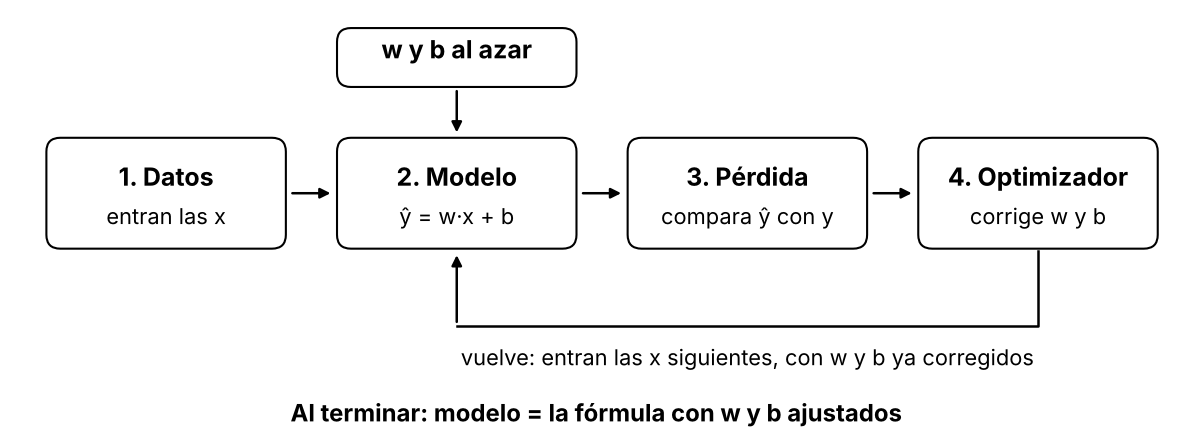

### Inicio: w y b al azar

El entrenamiento arranca sin saber nada: los pesos se eligen al azar y el bias empieza en 0.

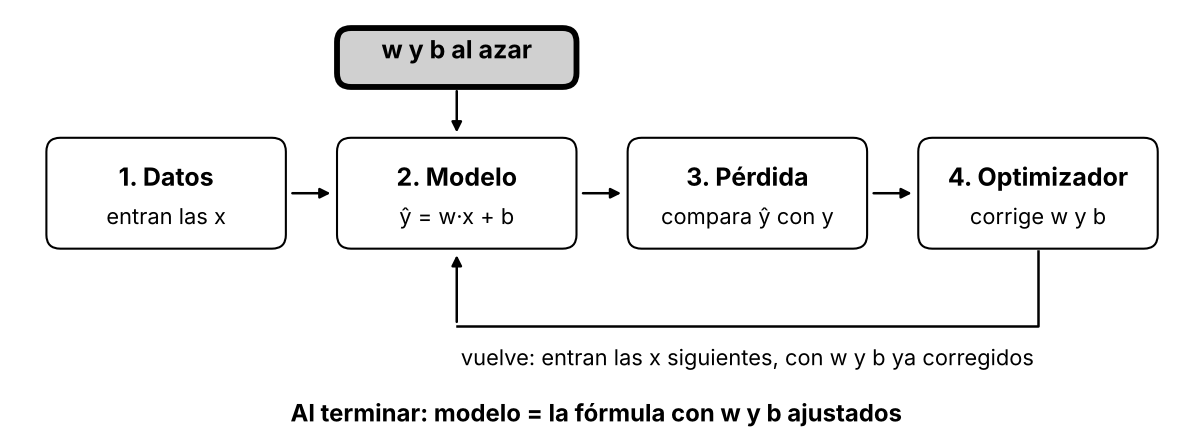

In [6]:
# Se crea un nuevo generador
rng_mano = np.random.default_rng(1)

# Generamos 3 pesos al azar entre 0 y 1
w = rng_mano.normal(0, 1, 3)

# El bias empieza en cero
b = 0.0
print("w =", w)
print("b =", b)

w = [0.346 0.822 0.33 ]
b = 0.0


### Caja 1: entran los datos

Tomamos la primera casa de la tabla.

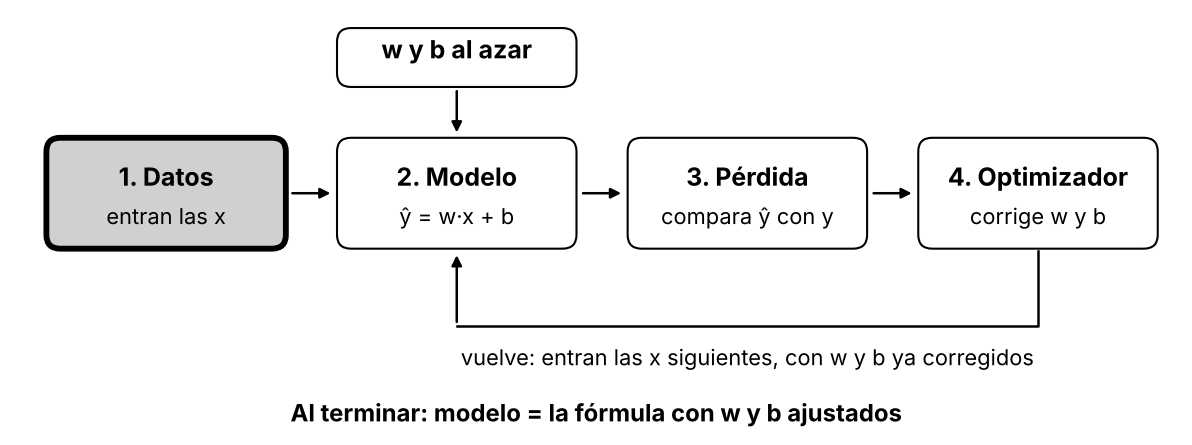

In [7]:
x = casas[["m2", "balcon", "ascensor"]].iloc[0].values
y = casas["precio"].iloc[0]
print("x =", x)
print("y =", y)

x = [42  0  1]
y = 93.8


### Caja 2: el modelo predice

La predicción se escribe **ŷ** ("y sombrero") para no confundirla con el precio real y.

**PREDICCIÓN 2.** Con esos pesos al azar, ¿la predicción va a estar cerca del precio real o lejos? ¿Por qué?

*Tu respuesta:* Va a estar lejos, ya que es la primera vez que el modelo toma contacto con los datos. "No conoce nada sobre ellos"

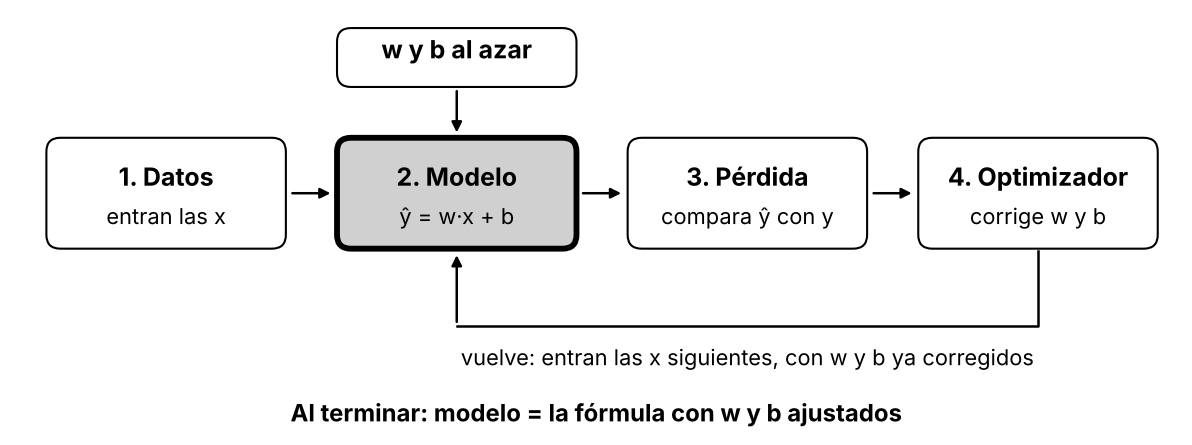

In [8]:
# Predecimos con los pesos al azar el valor de la primer casa
y_pred = w[0] * x[0] + w[1] * x[1] + w[2] * x[2] + b
print("ŷ =", round(y_pred, 2))
print("y =", y)

ŷ = 14.84
y = 93.8


### Caja 3: la pérdida mide cuánto se equivocó

La **pérdida** (loss) es un número que mide el error. Acá usamos el error al cuadrado: siempre da positivo, y castiga más los errores grandes.

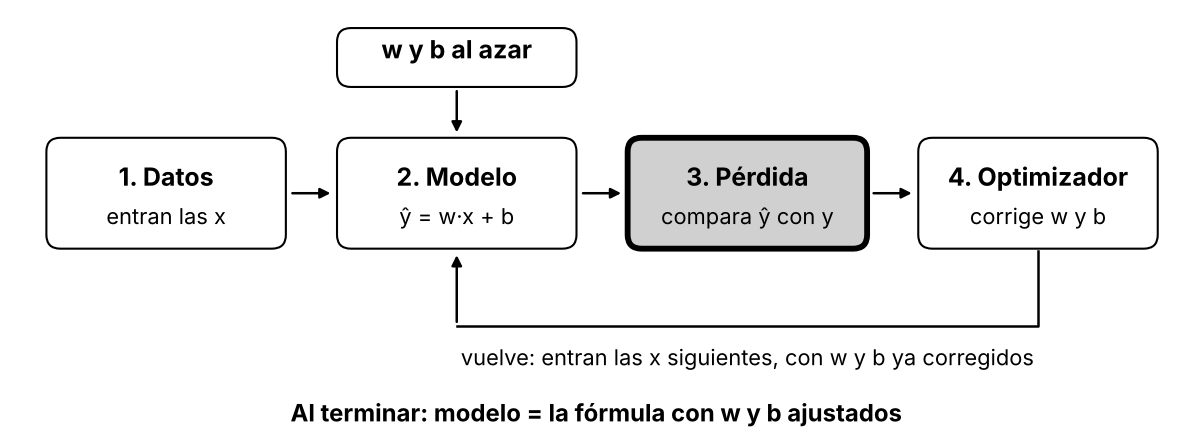

In [9]:
error = y_pred - y
perdida = error ** 2
print("error   = ŷ - y  =", round(error, 2))
print("pérdida = error² =", round(perdida, 2))

error   = ŷ - y  = -78.96
pérdida = error² = 6233.9


### Caja 4: el optimizador corrige w y b

El **optimizador** se pregunta, para cada parámetro (cada peso y el bias): *si lo muevo un poquito, ¿el error sube o baja, y cuánto?* La respuesta es el **gradiente**. Para esta fórmula:

- gradiente de cada peso: 2 · error · x
- gradiente del bias: 2 · error

Después corrige cada parámetro en sentido contrario al gradiente:

  **parámetro = parámetro − tasa × gradiente**

(Nota agregada por mi: es por el signo negativo que corrige en sentido contrario. En éste ejemplo el error es negativo, por lo que el gradiente también es negativo, pero por el signo negativo aumenta el parámetro)

La **tasa de aprendizaje** dice qué tan grande es el "paso" o el ajuste o corrección del gradiente. No la aprende el algoritmo: la elegís vos. Por eso es un **hiperparámetro**. En cambio, w y b son **parámetros**: los aprende el algoritmo.

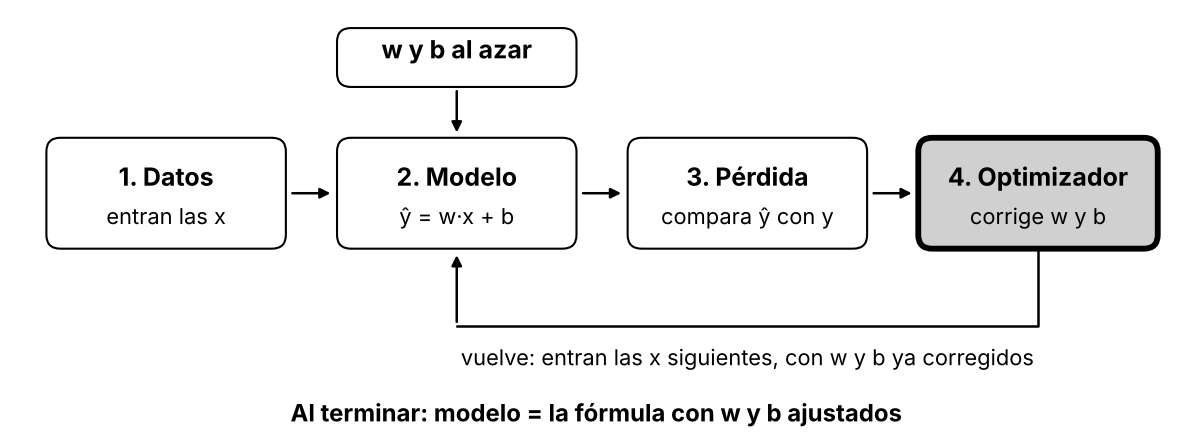

In [10]:
# Definimos los gradientes para los pesos y el bias para ésta
# primer vuelta
grad_w = 2 * error * x
grad_b = 2 * error
print("gradiente de w =", grad_w)
print("gradiente de b =", round(grad_b, 2))

gradiente de w = [-6632.222    -0.     -157.91 ]
gradiente de b = -157.91


Mirá los signos: si el gradiente es negativo, la corrección **sube** ese parámetro. Y el de `m2` es mucho más grande que los otros porque `m2` vale mucho más que 0 o 1.

In [11]:
tasa = 0.0001     # hiperparámetro

w = w - tasa * grad_w
b = b - tasa * grad_b
print("w corregido =", w)
print("b corregido =", round(b, 4))

w corregido = [1.009 0.822 0.346]
b corregido = 0.0158


### La vuelta: ¿mejoró?

Con los parámetros corregidos, la misma casa:

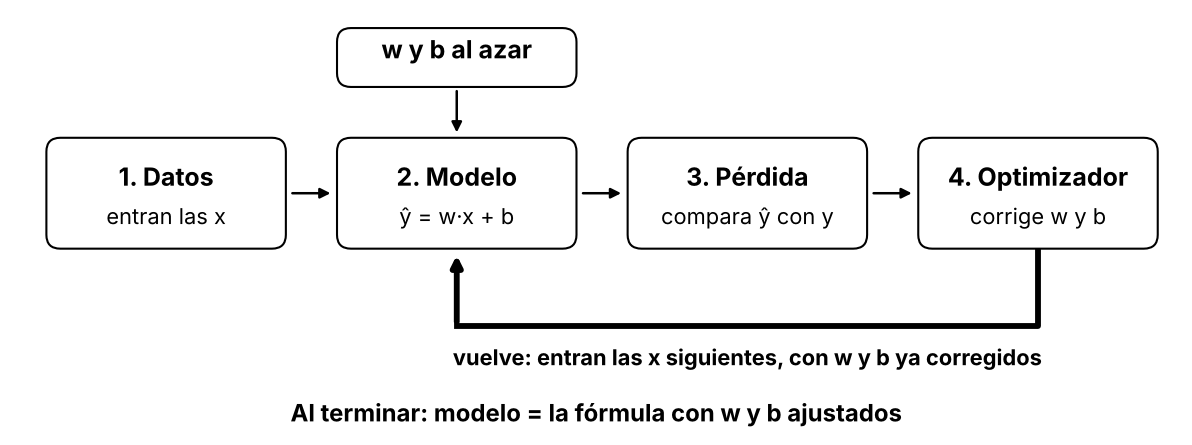

In [12]:
#
y_pred_nueva = w[0] * x[0] + w[1] * x[1] + w[2] * x[2] + b
print("antes:   ŷ =", round(y_pred, 2), "  pérdida =", round(perdida, 2))
print("después: ŷ =", round(y_pred_nueva, 2), "  pérdida =", round((y_pred_nueva - y) ** 2, 2))

antes:   ŷ = 14.84   pérdida = 6233.9
después: ŷ = 42.73   pérdida = 2607.95


Una sola corrección ya bajó el error para esa casa.

### ¿Y después? Filas, vueltas y épocas

La vuelta **no se repite sobre la misma fila**. Si siguiéramos corrigiendo con la primera casa, los parámetros terminarían sirviendo solo para esa casa. Lo que sigue es:

1. Entra la **segunda** casa, con los w y b que dejó la primera. Predice, mide, corrige.
2. Entra la tercera, con los w y b que dejó la segunda. Y así hasta la última.
3. Cuando pasaron **todas** las filas una vez, terminó una **época**.
4. Empieza la época siguiente: vuelve a entrar la primera casa, pero ahora con los w y b que dejó la última.

Más adelante vamos a entrenar con 160 de las 200 casas (en la sección 3 se ve por qué). Con 160 casas y 50 épocas, cada casa entra 50 veces y w y b se corrigen 160 × 50 = 8000 veces. La cantidad de épocas no la aprende el algoritmo: la elegís vos, así que es otro **hiperparámetro**.

Hay tres formas de hacer entrar las filas, y en este notebook vas a ver dos:

| Forma | Qué entra en cada vuelta | Correcciones por época | Dónde la vas a ver |
|---|---|---|---|
| Fila por fila | 1 fila | 160 (una por fila) | `SGDRegressor` |
| Todas juntas | las 160 filas; se promedia la pérdida | 1 | PyTorch y Keras, en este notebook |
| De a lotes | un grupo de filas, por ejemplo 32 | 160 / 32 = 5 | lo más común en redes neuronales |

En las tres, el camino es el mismo: lo único que cambia es cuántas filas entran antes de cada corrección. Ese número se llama **tamaño de lote** (batch size), y también es un hiperparámetro.

Hacerlo a mano para 160 casas y cientos de épocas no tiene sentido: para eso están las librerías.

## 3. scikit-learn

Primero separamos los datos. El modelo se entrena con una parte (**train**) y se evalúa con otra que no vio (**test**), para saber si anda bien con casas nuevas.

In [13]:
from sklearn.model_selection import train_test_split

X = casas[["m2", "balcon", "ascensor"]]
y = casas["precio"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print("train:", len(X_train), "casas")
print("test: ", len(X_test), "casas")

train: 160 casas
test:  40 casas


### 3.1 `LinearRegression`

`fit` recibe las x y las y de entrenamiento y ajusta los parámetros.

Documentación oficial: [sklearn.linear_model.LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)

In [14]:
from sklearn.linear_model import LinearRegression

# LinearRegression() es la clase
# lineal es una instancia u objeto
lineal = LinearRegression()
lineal.fit(X_train, y_train)

LinearRegression()

In [15]:
# .coef_ con los coeficientes de la función lineal y los pesos
# del modelo, mientras que el intercept_ es el bias
print("w =", lineal.coef_)
print("b =", round(lineal.intercept_, 2))

w = [ 1.503  8.625 12.565]
b = 19.27


Compará con tu PREDICCIÓN 1.

Todo lo que `fit` aprende termina con guion bajo: `coef_` son los pesos, `intercept_` es el bias.

Un detalle: `LinearRegression` **no** recorre el camino. Para este modelo existe una fórmula matemática que calcula los mejores w y b de una sola vez (mínimos cuadrados). Para ver el camino, scikit-learn tiene otro algoritmo.

### 3.2 `SGDRegressor`: el mismo modelo, recorriendo el camino

`SGDRegressor` hace lo mismo que hicimos a mano, **fila por fila**: entra una casa, predice, mide la pérdida y corrige; entra la siguiente con los parámetros corregidos, y así. Al terminar cada época, mezcla el orden de las filas y empieza otra vez. `eta0` es la tasa de aprendizaje.

Documentación oficial: [sklearn.linear_model.SGDRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDRegressor.html)

**PREDICCIÓN 3.** ¿Va a llegar a los mismos w y b que `LinearRegression`?

*Tu respuesta:* $NO$

**ERROR INTENCIONAL**

In [16]:
from sklearn.linear_model import SGDRegressor

sgd = SGDRegressor(eta0=0.01, learning_rate="constant", penalty=None, random_state=0)
sgd.fit(X_train, y_train)

SGDRegressor(learning_rate='constant', penalty=None, random_state=0)

Leé el mensaje de error: ¿qué sugiere hacer?

Pasó lo que se veía en la vuelta a mano: el gradiente de `m2` es enorme porque `m2` vale cerca de 100, mientras que `balcon` vale 0 o 1. Con esta tasa, cada corrección se pasa de largo, el error crece y la corrección siguiente es todavía más grande, hasta que los números desbordan.

### 3.3 La transformación: escalar las x

La solución es poner todas las x en la misma escala antes de que entren al modelo. Eso es una **transformación**.

`StandardScaler` resta el promedio de cada columna y divide por su desvío. Después de escalar, todas las columnas quedan con promedio 0 y desvío 1.

El scaler **también tiene `fit`**: lo que aprende es el promedio y el desvío de cada columna. Se ajusta solo con train.

Documentación oficial: [sklearn.preprocessing.StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [17]:
from sklearn.preprocessing import StandardScaler

# StandardScaler() -> clase
# scaler -> instancia
scaler = StandardScaler()
scaler.fit(X_train)

print("promedio aprendido:", scaler.mean_)
print("desvío aprendido:  ", scaler.scale_)

promedio aprendido: [76.237  0.463  0.494]
desvío aprendido:   [23.274  0.499  0.5  ]


Atención! a *x_test* se aplica directamente **.transform()**:

In [18]:
X_train_esc = scaler.transform(X_train)
X_test_esc = scaler.transform(X_test)

print("primera casa, original:", X_train.iloc[0].values)
print("primera casa, escalada:", X_train_esc[0])

primera casa, original: [103   0   1]
primera casa, escalada: [ 1.15  -0.928  1.013]


Ahora sí, `SGDRegressor` con las x escaladas. Lo entrenamos de a una época con `partial_fit` para ver cómo baja la pérdida.

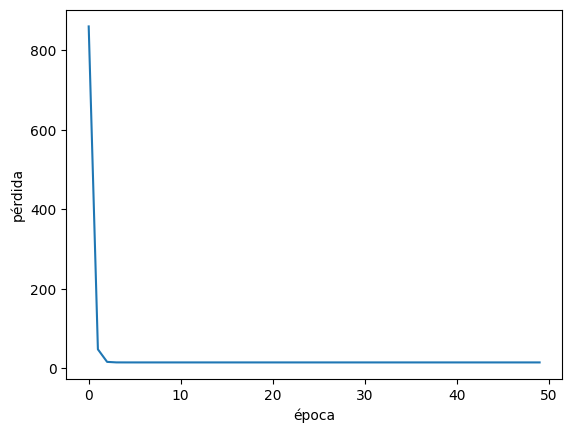

In [19]:
from sklearn.metrics import mean_squared_error

sgd = SGDRegressor(eta0=0.01, learning_rate="constant", penalty=None, random_state=0)
perdidas_sgd = []

# Para cada época se calcula el Error Cuadrático Medio
# y se grafica
for epoca in range(50):
    sgd.partial_fit(X_train_esc, y_train)
    perdidas_sgd.append(mean_squared_error(y_train, sgd.predict(X_train_esc)))

plt.plot(perdidas_sgd)
plt.xlabel("época"); plt.ylabel("pérdida")
plt.show()

Para comparar con `LinearRegression` hay que darle las mismas x escaladas: al cambiar la escala de las x, cambian los pesos (un peso por "desvío de m²" no es lo mismo que un peso por m²).

In [20]:
lineal_esc = LinearRegression().fit(X_train_esc, y_train)

print("LinearRegression  w =", lineal_esc.coef_, "  b =", round(lineal_esc.intercept_, 2))
print("SGDRegressor      w =", sgd.coef_, "  b =", round(sgd.intercept_[0], 2))

LinearRegression  w = [34.989  4.301  6.282]   b = 144.08
SGDRegressor      w = [34.946  4.076  6.316]   b = 144.04


Respuesta a la PREDICCIÓN 3: llegan a valores muy parecidos por dos caminos distintos. Uno con una fórmula de una vez, el otro corrigiendo de a poco.

## 4. PyTorch: el camino escrito por vos

En PyTorch no hay `fit`: el ciclo de entrenamiento se escribe a mano. Cada línea corresponde a una caja del diagrama.

| Caja | PyTorch |
|---|---|
| w y b al azar | `nn.Linear(3, 1)` |
| 2. Modelo | `y_pred = modelo_pt(X)` |
| 3. Pérdida | `perdida = criterio(y_pred, y)` |
| 4. Optimizador | `perdida.backward()` calcula el gradiente, `optimizador.step()` corrige |
| vuelve | el `for` |

### Primero: convertir los datos a tensores

Hasta acá los datos estuvieron en una tabla de pandas (`X_train`) o en un array de NumPy (`X_train_esc`). PyTorch no trabaja con ninguno de los dos: solo opera con su propio tipo de dato, el **tensor**.

Un tensor es, como un array de NumPy, una grilla de números: un número suelto, una lista, una tabla o más dimensiones. La diferencia es que el tensor puede hacer dos cosas que el array no:

- **Calcular el gradiente solo.** Mientras el modelo hace sus cuentas, PyTorch registra cada operación. Después, `backward()` recorre ese registro hacia atrás y calcula el gradiente de cada parámetro. Es lo que en la vuelta a mano hicimos con `grad_w = 2 * error * x`, pero automático y para cualquier fórmula.
- **Pasar a la placa de video (GPU)** para hacer las cuentas mucho más rápido. Acá no lo necesitamos.

Por eso, antes de entrenar, hay que convertir los datos.

Documentación oficial: [torch.Tensor](https://pytorch.org/docs/stable/tensors.html)

(Nota: El módulo *torch.nn* de PyTorch proporciona todas las clases y funciones necesarias para construir y entrenar redes neuronales artificiales en Python.

La clase *torch.nn.Linear* de PyTorch aplica una transformación lineal a los datos de entrada mediante la ecuación matemática $y = xW^T + b$. Implementa una capa totalmente conectada (fully connected layer) donde cada neurona de entrada se conecta con cada neurona de salida.)

In [21]:
import torch
from torch import nn

# Conversion a tensor de las features escaladas
Xt = torch.tensor(X_train_esc, dtype=torch.float32)
print(type(X_train_esc), X_train_esc.dtype, X_train_esc.shape)
print(type(Xt), Xt.dtype, Xt.shape)

<class 'numpy.ndarray'> float64 (160, 3)
<class 'torch.Tensor'> torch.float32 torch.Size([160, 3])


Las 160 casas con sus 3 características, ahora como tensor. Dos detalles de la conversión:

- `dtype=torch.float32`: NumPy guarda los decimales en `float64` y PyTorch crea sus pesos en `float32`. Si los datos y los pesos son de tipos distintos, PyTorch no hace la cuenta y da error. Por eso convertimos los datos al tipo de los pesos.

In [22]:
# Conversión a tensor de los y de entrenamiento
yt = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
print("y como lista:  ", torch.tensor(y_train.values).shape)
print("y como columna:", yt.shape)

y como lista:   torch.Size([160])
y como columna: torch.Size([160, 1])


- `reshape(-1, 1)`: el modelo devuelve una predicción por fila **en forma de columna**, (160, 1). Las y tienen que tener la misma forma para que la pérdida compare cada ŷ con su y. `-1` significa "calculá vos cuántas filas son".

### Inicio: w y b al azar

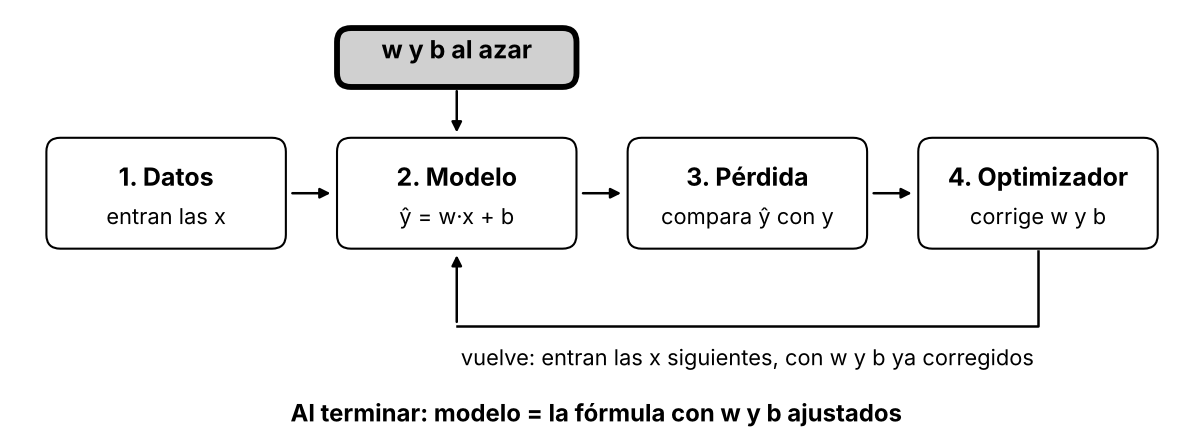

In [23]:
# PRIMERA VUELTA

# Semilla
torch.manual_seed(0)

# Creamos la red neuronal de 3 entradas y 1 salida
modelo_pt = nn.Linear(3, 1)

print("w =", modelo_pt.weight.data)
print("b =", modelo_pt.bias.data)

w = tensor([[-0.0043,  0.3097, -0.4752]])
b = tensor([-0.4249])


`nn.Linear(3, 1)` es exactamente ŷ = w1·x1 + w2·x2 + w3·x3 + b: 3 entradas, 1 salida (Vector de entradas $x_1$, $x_2$, $x_3$ y una salida $\hat{y}$).

Definimos la pérdida y el optimizador. `MSELoss` es el promedio de los errores al cuadrado de todas las filas (**MSE**, error cuadrático medio). `lr` es la tasa de aprendizaje.

Documentación oficial: [torch.nn.Linear](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) · [torch.nn.MSELoss](https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html) · [torch.optim.SGD](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html)

In [24]:
criterio = nn.MSELoss()
optimizador = torch.optim.SGD(modelo_pt.parameters(), lr=0.1)

### Una vuelta, caja por caja

En PyTorch vamos a usar la forma **todas juntas**: en cada vuelta entran las 160 casas a la vez, la pérdida es el promedio de los 160 errores y se hace una sola corrección. Así, cada vuelta es una época.

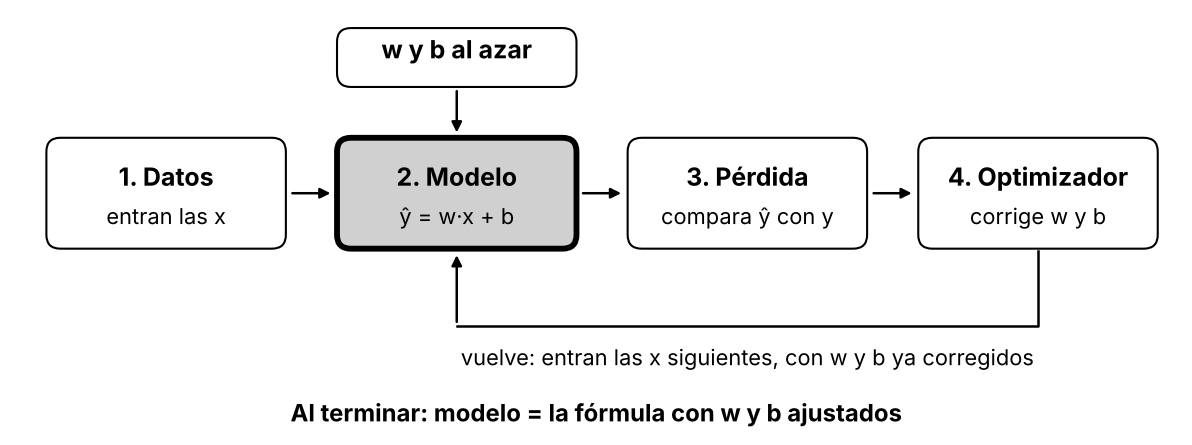

In [25]:
y_pred = modelo_pt(Xt)
print("primeras 3 predicciones:", y_pred[:3].detach().ravel())
print("primeros 3 precios:     ", yt[:3].ravel())

primeras 3 predicciones: tensor([-1.1983, -0.2496, -0.5708])
primeros 3 precios:      tensor([184.1000, 192.3000, 146.8000])


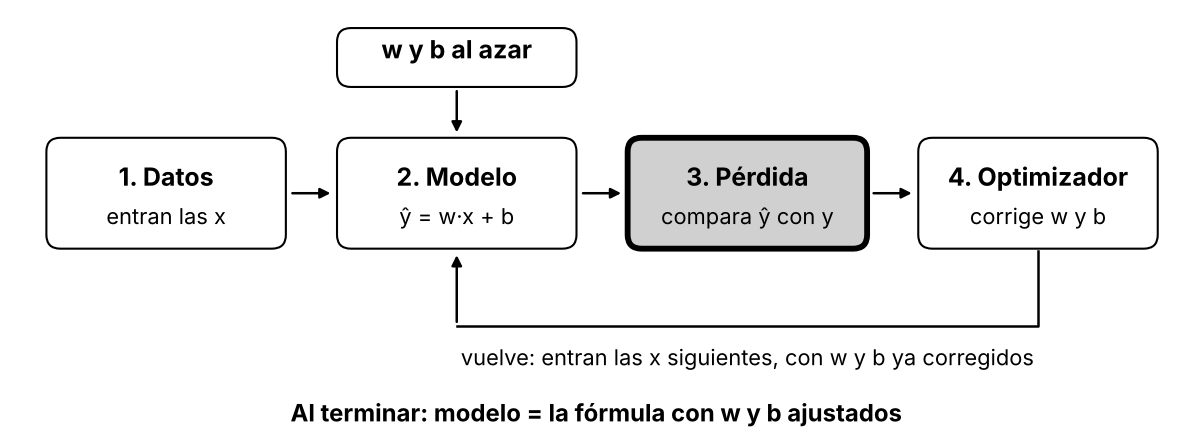

In [26]:
perdida = criterio(y_pred, yt)
print("pérdida =", perdida.item())

pérdida = 22152.091796875


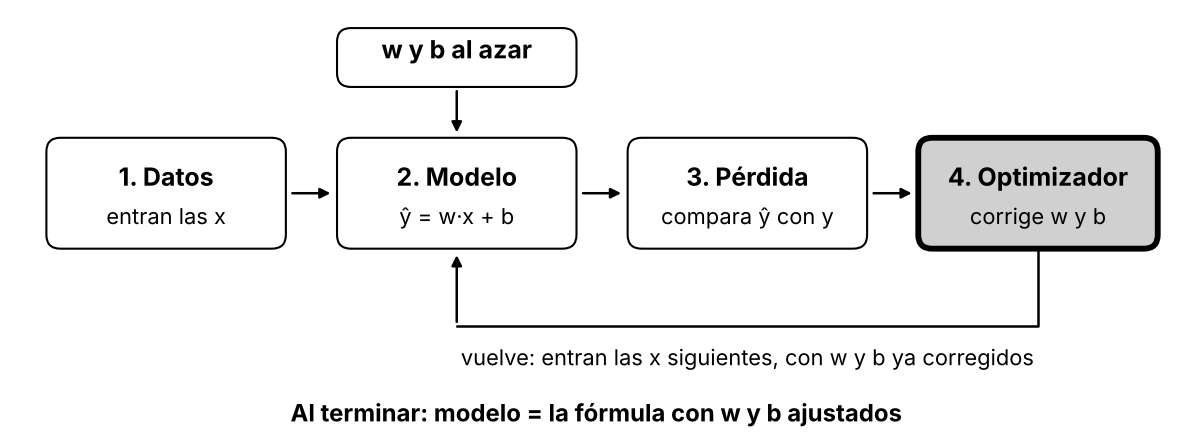

In [27]:
# Borrado del gradiente anterior, en caso de estar almacenado
optimizador.zero_grad()

# Cálculo del gradiente de éste paso
perdida.backward()
print("gradiente de w =", modelo_pt.weight.grad)
print("gradiente de b =", modelo_pt.bias.grad)

gradiente de w = tensor([[-69.2402,  -5.8190,  -9.5076]])
gradiente de b = tensor([-289.0098])


In [28]:
# Corrección de los pesos y el bias
optimizador.step()
print("w corregido =", modelo_pt.weight.data)
print("b corregido =", modelo_pt.bias.data)

w corregido = tensor([[6.9197, 0.8916, 0.4756]])
b corregido = tensor([28.4761])


### Ahora, muchas vueltas

Las mismas líneas, dentro de un `for`. Como cada vuelta usa las 160 casas, `range(200)` son 200 épocas y 200 correcciones.

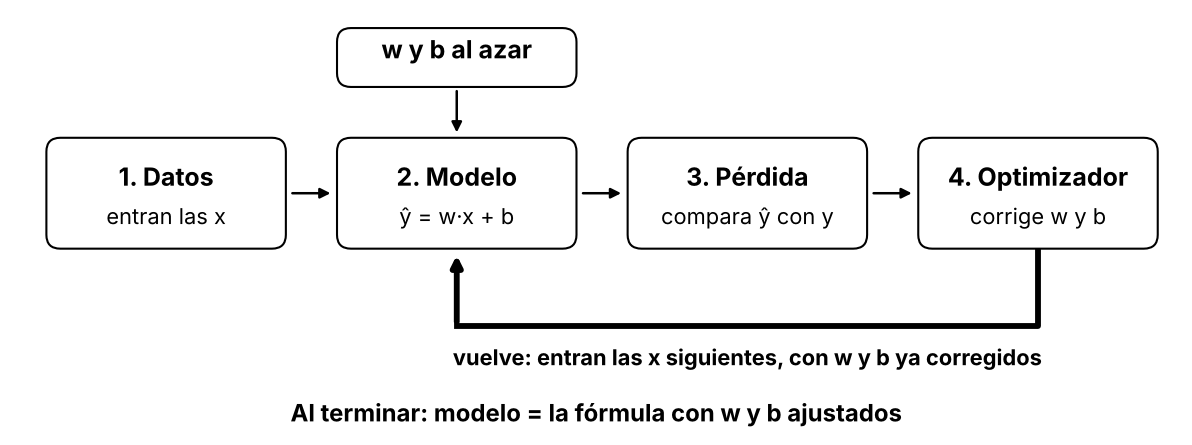

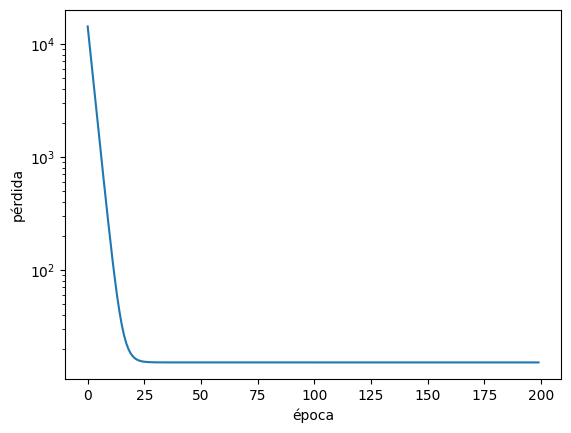

In [29]:
perdidas_pt = []
for epoca in range(200):
    y_pred = modelo_pt(Xt)                 # 2. modelo
    perdida = criterio(y_pred, yt)         # 3. pérdida
    optimizador.zero_grad()
    perdida.backward()                     # 4. gradiente
    optimizador.step()                     # 4. corrección
    perdidas_pt.append(perdida.item())

plt.plot(perdidas_pt)
plt.xlabel("época"); plt.ylabel("pérdida"); plt.yscale("log")
plt.show()

In [30]:
print("PyTorch           w =", modelo_pt.weight.data.ravel(), "  b =", round(modelo_pt.bias.item(), 2))
print("LinearRegression  w =", lineal_esc.coef_, "  b =", round(lineal_esc.intercept_, 2))

PyTorch           w = tensor([34.9893,  4.3006,  6.2822])   b = 144.08
LinearRegression  w = [34.989  4.301  6.282]   b = 144.08


**PREDICCIÓN 4.** Si la tasa de aprendizaje pasa de 0.1 a 1.0, el paso de cada corrección es 10 veces más grande. ¿El modelo aprende más rápido, igual o peor?

*Tu respuesta:* Rápido, pero peor.

In [31]:
torch.manual_seed(0)
modelo_rapido = nn.Linear(3, 1)
optimizador_rapido = torch.optim.SGD(modelo_rapido.parameters(), lr=1.0)

for epoca in range(8):
    perdida = criterio(modelo_rapido(Xt), yt)
    optimizador_rapido.zero_grad()
    perdida.backward()
    optimizador_rapido.step()
    print(f"época {epoca}   pérdida {perdida.item():,.0f}")

época 0   pérdida 22,152
época 1   pérdida 22,069
época 2   pérdida 22,052
época 3   pérdida 22,083
época 4   pérdida 22,156
época 5   pérdida 22,269
época 6   pérdida 22,431
época 7   pérdida 22,652


Con un paso demasiado grande, cada corrección se pasa del mínimo y cae más lejos del otro lado. La pérdida no baja: crece. Elegir los hiperparámetros también es parte del trabajo.

## 5. Keras: el mismo ciclo, adentro de `fit`

Keras vuelve a tener `fit`. Ahora sabés qué hace por dentro: el mismo `for` de PyTorch. Vos le decís qué pérdida, qué optimizador y cuántas épocas, y Keras arma el ciclo.

**Dense** es el nombre de Keras para la misma capa lineal: ŷ = w·x + b.

A diferencia de PyTorch, a Keras le podés pasar directamente los arrays de NumPy: la conversión a tensores la hace `fit` por dentro.

Documentación oficial: [keras.layers.Dense](https://keras.io/api/layers/core_layers/dense/) · [Model.fit](https://keras.io/api/models/model_training_apis/)

In [32]:
import keras

# Semilla
keras.utils.set_random_seed(0)

# keras.Sequential() es el análogo de nn.linear() de PyTorch
# layer -> capa
# keras.Sequential() -> clase
# modelo_k -> instancia
modelo_k = keras.Sequential([keras.Input(shape=(3,)), keras.layers.Dense(1)])

w_k, b_k = modelo_k.layers[0].get_weights()
print("w al azar =", w_k.ravel())
print("b al azar =", b_k)

w al azar = [ 0.038 -0.468  0.83 ]
b al azar = [0.]


**.compile()** es un método de los modelos en keras. Permite definir el optimizador y como estimar la pérdida (en éste caso, el $MSE$ o Error Cuadrático Medio).

In [33]:
modelo_k.compile(optimizer=keras.optimizers.SGD(learning_rate=0.1), loss="mse")

**PREDICCIÓN 5.** En PyTorch, el ciclo ocupó un `for` con cinco líneas. ¿Cuántas líneas va a ocupar en Keras?

*Tu respuesta:*

In [34]:
# Definición de las particiones de entrenamiento - Cantidad
# de épocas y tamaño de lote o batch
# verbose: cantidad de info que se muestra por pantalla
historia = modelo_k.fit(X_train_esc, y_train.values, epochs=200, batch_size=len(X_train_esc), verbose=0)

`epochs=200` es la cantidad de épocas. `batch_size` es el tamaño de lote: cuántas filas entran antes de cada corrección. Con `batch_size=len(X_train_esc)` entran las 160 juntas, igual que en PyTorch. Si no lo indicás, Keras usa lotes de 32 filas.

`fit` de Keras devuelve el historial de la pérdida. Los parámetros quedan guardados adentro del modelo.

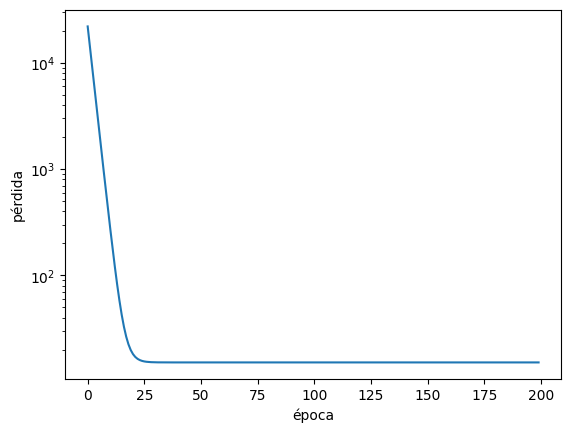

Keras             w = [34.989  4.301  6.282]   b = 144.08
LinearRegression  w = [34.989  4.301  6.282]   b = 144.08


In [35]:
plt.plot(historia.history["loss"])
plt.xlabel("época"); plt.ylabel("pérdida"); plt.yscale("log")
plt.show()

w_k, b_k = modelo_k.layers[0].get_weights()
print("Keras             w =", w_k.ravel(), "  b =", round(float(b_k[0]), 2))
print("LinearRegression  w =", lineal_esc.coef_, "  b =", round(lineal_esc.intercept_, 2))

## 6. ¿Anda bien? Evaluar con casas que no vio

Ahora usamos test: las 40 casas que ningún modelo vio al entrenar. Dos medidas:

- **RMSE**: cuánto se equivoca en promedio, en miles de US$ (es la raíz del MSE).
- **R²**: qué parte de las diferencias de precio entre casas explica el modelo. 1 es perfecto; 0 es lo mismo que decir siempre el precio promedio.

In [36]:
from sklearn.metrics import r2_score

predicciones = {
    "LinearRegression": lineal_esc.predict(X_test_esc),
    "SGDRegressor": sgd.predict(X_test_esc),
    "PyTorch": modelo_pt(torch.tensor(X_test_esc, dtype=torch.float32)).detach().numpy().ravel(),
    "Keras": modelo_k.predict(X_test_esc, verbose=0).ravel(),
}
for nombre, p in predicciones.items():
    rmse = mean_squared_error(y_test, p) ** 0.5
    print(f"{nombre:17}  RMSE = {rmse:5.2f} miles de US$   R² = {r2_score(y_test, p):.3f}")

LinearRegression   RMSE =  4.42 miles de US$   R² = 0.982
SGDRegressor       RMSE =  4.38 miles de US$   R² = 0.982
PyTorch            RMSE =  4.42 miles de US$   R² = 0.982
Keras              RMSE =  4.42 miles de US$   R² = 0.982


Los cuatro dan prácticamente lo mismo: son la misma fórmula con casi los mismos parámetros.

El dataset se generó con estos valores, más un poco de ruido al azar que ningún modelo puede predecir:

| | w1 (m²) | w2 (balcón) | w3 (ascensor) | b |
|---|---|---|---|---|
| Valores con que se generó | 1.5 | 8 | 12 | 20 |

Compará con lo que encontró `LinearRegression` en la sección 3.1 y con tu PREDICCIÓN 1.

Si tu estimación del balcón o del ascensor dio más alta que el valor real, mirá los promedios de m² de esas tablas: las casas con balcón (o con ascensor) eran, en promedio, un poco más grandes. Parte de la diferencia de precio venía de los m², no del balcón. Separar a mano el efecto de cada característica es difícil; la regresión lineal lo hace con todas a la vez.

## 7. Entonces, ¿qué es un modelo?

Un **modelo** es la fórmula con los parámetros ya ajustados. Recibe x y devuelve ŷ.

Con los w y b que encontró `LinearRegression`, el precio de la casa nueva del principio se puede calcular a mano:

In [37]:
w, b = lineal.coef_, lineal.intercept_
casa_nueva = pd.DataFrame({"m2": [65], "balcon": [1], "ascensor": [0]})

a_mano = w[0] * 65 + w[1] * 1 + w[2] * 0 + b
print(f"a mano:  {w[0]:.2f}·65 + {w[1]:.2f}·1 + {w[2]:.2f}·0 + {b:.2f} = {a_mano:.1f}")
print(f"predict: {lineal.predict(casa_nueva)[0]:.1f}")

a mano:  1.50·65 + 8.63·1 + 12.57·0 + 19.27 = 125.6
predict: 125.6


Pero los modelos que recorrieron el camino aprendieron con x **escaladas**. Para usarlos, la casa nueva tiene que pasar primero por el mismo scaler. Por eso, el modelo completo es: **transformación + fórmula con sus parámetros**.

En scikit-learn eso se arma con un **Pipeline**: el scaler y el regresor quedan encadenados, y `predict` recibe las x originales.

In [38]:
from sklearn.pipeline import make_pipeline

pipeline = make_pipeline(StandardScaler(), LinearRegression())
pipeline.fit(X_train, y_train)
print("casa nueva:", pipeline.predict(casa_nueva)[0].round(1), "miles de US$")

casa nueva: 125.6 miles de US$


## 8. Exportar el modelo

**Exportar** es guardar el modelo en un archivo para usarlo en otro lado (una app de Gradio, un Space de Hugging Face) sin volver a entrenar.

En clase exportamos uno por librería. Los demás formatos los investigan en la Actividad del final.

In [39]:
from pathlib import Path
CARPETA = Path("modelos_exportados")
CARPETA.mkdir(exist_ok=True)

### 8.1 scikit-learn: joblib

In [40]:
import joblib

joblib.dump(pipeline, CARPETA / "casas.joblib")

['modelos_exportados/casas.joblib']

Hacemos de cuenta que somos otra persona que solo tiene el archivo:

In [41]:
modelo_cargado = joblib.load(CARPETA / "casas.joblib")
print("casa nueva:", modelo_cargado.predict(casa_nueva)[0].round(1))

casa nueva: 125.6


¿Qué hay adentro? El Pipeline completo, con los parámetros de sus dos pasos:

In [42]:
scaler_cargado, regresor_cargado = modelo_cargado[0], modelo_cargado[1]
print("scaler:   promedio =", scaler_cargado.mean_, "  desvío =", scaler_cargado.scale_)
print("regresor: w =", regresor_cargado.coef_, "  b =", round(regresor_cargado.intercept_, 2))

scaler:   promedio = [76.237  0.463  0.494]   desvío = [23.274  0.499  0.5  ]
regresor: w = [34.989  4.301  6.282]   b = 144.08


**PREDICCIÓN 6.** Ahora exportamos solo `lineal_esc`, el regresor que aprendió con x escaladas, **sin** el scaler. Otra persona lo carga y le pasa la casa nueva. ¿Qué precio va a devolver?

*Tu respuesta:* Error o un valor sin sentido

**ERROR INTENCIONAL**

In [43]:
joblib.dump(lineal_esc, CARPETA / "casas_sin_scaler.joblib")

otro = joblib.load(CARPETA / "casas_sin_scaler.joblib")
print("casa nueva:", otro.predict(casa_nueva.values)[0].round(1), "miles de US$")

casa nueva: 2422.7 miles de US$


No da ningún error, pero el precio está mal. El modelo espera x escaladas (valores cerca de 0) y recibió 65. Es el peor tipo de error: devuelve un número que parece válido.

Conclusión: **la transformación tiene que viajar con el modelo**. En scikit-learn, exportando el Pipeline. En PyTorch y Keras, guardando el scaler junto con el modelo.

### 8.2 PyTorch: state_dict

El `state_dict` es un diccionario con los parámetros del modelo.

In [44]:
torch.save(modelo_pt.state_dict(), CARPETA / "casas_pt.pt")
joblib.dump(scaler, CARPETA / "casas_pt_scaler.joblib")      # la transformación, aparte

print(torch.load(CARPETA / "casas_pt.pt"))

OrderedDict({'weight': tensor([[34.9893,  4.3006,  6.2822]]), 'bias': tensor([144.0800])})


Ahí están w (`weight`) y b (`bias`). Pero solo están los números: para usarlos hay que volver a crear la fórmula vacía y cargarlos adentro.

In [45]:
# Creamos la instancia
modelo_nuevo = nn.Linear(3, 1)
# Guardamos los pesos en el modelo vacío
modelo_nuevo.load_state_dict(torch.load(CARPETA / "casas_pt.pt"))

# Lo mismo con las transformaciones
scaler_pt = joblib.load(CARPETA / "casas_pt_scaler.joblib")
x_nueva = torch.tensor(scaler_pt.transform(casa_nueva), dtype=torch.float32)
print("casa nueva:", round(modelo_nuevo(x_nueva).item(), 1))

casa nueva: 125.6


### 8.3 Keras: .keras

In [46]:
modelo_k.save(CARPETA / "casas.keras")
joblib.dump(scaler, CARPETA / "casas_keras_scaler.joblib")

['modelos_exportados/casas_keras_scaler.joblib']

Un archivo `.keras` es un zip. Veamos qué tiene:

In [47]:
import zipfile
with zipfile.ZipFile(CARPETA / "casas.keras") as z:
    print(z.namelist())

['metadata.json', 'config.json', 'model.weights.h5']


`config.json` describe la arquitectura (una capa Dense con una salida) y `model.weights.h5` tiene los parámetros. A diferencia del state_dict de PyTorch, no hace falta volver a escribir la fórmula para cargarlo:

In [48]:
modelo_k_cargado = keras.models.load_model(CARPETA / "casas.keras")
scaler_k = joblib.load(CARPETA / "casas_keras_scaler.joblib")
print("casa nueva:", round(modelo_k_cargado.predict(scaler_k.transform(casa_nueva), verbose=0).item(), 1))

casa nueva: 125.6


## ACTIVIDAD — ¿Qué guarda cada formato?

Cada librería tiene más formatos de exportación que los tres que vimos. La actividad es individual:

1. Anotate con **un** formato de la tabla en la planilla del aula virtual. Si todos los formatos ya tienen a alguien anotado, elegí uno que tenga una sola persona.
2. Exportá el modelo en ese formato desde este notebook, con el modelo de la sección que corresponde.
3. Respondé las preguntas.

Preguntas:

1. ¿Qué guarda: solo los parámetros, la arquitectura, código? Mostrá dónde están w y b.
2. ¿Para cargarlo hace falta la misma librería? ¿Hace falta volver a escribir la fórmula?
3. ¿Es seguro abrir un archivo de este formato que te mandó un desconocido? Buscalo en la documentación oficial.
4. ¿Para qué caso lo elegirías: una app de Gradio, un celular, compartirlo en Hugging Face Hub, seguir entrenando?

Podés responder por escrito en una celda de texto o mostrarlo con código.

| Formato | Librería | Para exportar |
|---|---|---|
| pickle | scikit-learn | `pickle.dump(pipeline, open("casas.pkl", "wb"))` |
| skops | scikit-learn | `skops.io.dump(pipeline, "casas.skops")` |
| ONNX | scikit-learn | `skl2onnx.to_onnx(pipeline, X_train.values.astype("float32"))` |
| modelo completo | PyTorch | `torch.save(modelo_pt, "casas_completo.pt")` |
| TorchScript | PyTorch | `torch.jit.trace(modelo_pt, x_nueva).save("casas_ts.pt")` |
| torch.export | PyTorch | `torch.export.save(torch.export.export(modelo_pt, (x_nueva,)), "casas.pt2")` |
| .weights.h5 | Keras | `modelo_k.save_weights("casas.weights.h5")` |
| SavedModel / TFLite | Keras | `modelo_k.export("casas_savedmodel")` |

Documentación oficial:

- scikit-learn: https://scikit-learn.org/stable/model_persistence.html
- PyTorch: https://pytorch.org/tutorials/beginner/saving_loading_models.html
- Keras: https://keras.io/guides/serialization_and_saving/
- ONNX: https://onnx.ai/onnx/intro/
- Hugging Face, sobre la seguridad de pickle: https://huggingface.co/docs/hub/security-pickle

## Para recordar

1. `fit` recorre el camino: predice, mide la pérdida, corrige w y b, y repite. Lo que aprende son **parámetros**; lo que configurás vos son **hiperparámetros**.
2. Un **modelo** es la fórmula con sus parámetros ajustados, más las transformaciones que necesitan sus entradas. La librería es solo la herramienta.
3. **Exportar** es guardar esos números, y a veces la arquitectura, en un archivo. Si la transformación no viaja con el modelo, el modelo predice mal sin avisar.

## Glosario

| Término | En inglés | Qué es |
|---|---|---|
| Característica / entrada | feature | Cada columna x que describe una fila (m², balcón, ascensor). |
| Etiqueta / salida | label, target | La columna y que se quiere predecir (precio). |
| Predicción | prediction | ŷ: lo que devuelve el modelo. |
| Peso | weight | Número que multiplica a cada x. |
| Bias | bias, intercept | Número que se suma al final: el valor de ŷ cuando todas las x valen 0. |
| Parámetros | parameters | Los pesos y el bias. Los aprende el algoritmo. |
| Hiperparámetros | hyperparameters | Configuración que elegís vos antes de entrenar: tasa de aprendizaje, épocas. |
| Pérdida | loss | Número que mide cuánto se equivoca el modelo. |
| MSE | mean squared error | Error cuadrático medio: el promedio de los errores al cuadrado. |
| Gradiente | gradient | Para cada parámetro, hacia dónde y cuánto moverlo para que baje la pérdida. |
| Optimizador | optimizer | La regla que corrige los parámetros usando el gradiente. |
| Tasa de aprendizaje | learning rate | El tamaño del paso de cada corrección. |
| Época | epoch | Una pasada completa por todas las filas de entrenamiento. |
| Tamaño de lote | batch size | Cuántas filas entran antes de cada corrección. |
| Tensor | tensor | El tipo de dato de PyTorch: una grilla de números que además registra las operaciones para calcular el gradiente. |
| Train / test | train / test | Filas para entrenar / filas que el modelo no ve, para evaluarlo. |
| Transformación | preprocessing | Cambio que se aplica a las x antes de entrar al modelo, como escalar. |
| Modelo | model | La fórmula con los parámetros ajustados: recibe x y devuelve ŷ. |
| Pipeline | pipeline | Transformación y modelo encadenados en un solo objeto. |
| Exportar | export, serialize | Guardar el modelo en un archivo para usarlo sin volver a entrenar. |

## Resolución de Actividad

El formato seleccionado para exportar el modelo es utilizar el método **.pikle()**.

Pickle es un módulo estándar de Python para serializar y deserializar objetos: convierte cualquier objeto de Python (listas, dics, incluso modelos de ML) en una secuencia de bytes almacenable en un archivo.

Para deserializar se realiza el proceso inverso: se lee el archivo y reconstruye el objeto tal cual estaba, listo para usar.

¿Por qué serializar datos? Porque en la mayoría de los casos, los datos no se hayan almacenados en memoria de forma contigua. Al hacerlo se reuno todo el contenido en un solo archivo, lo que a su vez facilita su transmisión.  


Pickle hace el mismo trabajo que **joblib** (incluso comparte algunos métodos), la diferencia es que éste último está construido específicamente para objetos constituidos por arreglos de NumPy, asegurando eficiencia y archivos más compactos.

1. ¿Qué guarda: solo los parámetros, la arquitectura, código? Mostrá dónde están w y b.

Guarda el modelo entero (pesos y bias, configuración interna y estado) en el mismo archivo serializado.

El parámetro "wb" le indica a **pickle** la escritura en modo binario:

In [50]:
# Se importa el módulo pickle sin instalación previa
import pickle

# .dump() para almacenar el modelo en un archivo
pickle.dump(pipeline, open(CARPETA / "casas.pkl", "wb"))

2. ¿Para cargarlo hace falta la misma librería? ¿Hace falta volver a escribir la fórmula?

Si, pero la misma es nativa de Python, solo con importarla alcanza. El método .load() carga directamente el modelo, listo para utilizarse.

El parámetro "rb" indica la lectura en modo binario:

In [54]:
# Volvemos a cargar el modelo serializado
modelo_cargado_pkl = pickle.load(open(CARPETA / "casas.pkl", "rb"))

# Verificamos que es el mismo modelo con los pesos y el bias, junto al
# escalador
scaler_cargado, regresor_cargado = modelo_cargado_pkl[0], modelo_cargado_pkl[1]
print("scaler:   promedio =", scaler_cargado.mean_, "  desvío =", scaler_cargado.scale_)
print("regresor: w =", regresor_cargado.coef_, "  b =", round(regresor_cargado.intercept_, 2))

scaler:   promedio = [76.237  0.463  0.494]   desvío = [23.274  0.499  0.5  ]
regresor: w = [34.989  4.301  6.282]   b = 144.08


3. ¿Es seguro abrir un archivo de este formato que te mandó un desconocido? Buscalo en la documentación oficial.

No, no se recomienda, ya que puede contener código malicioso. Se sugiere **pickle** para proyectos personales o en todo caso, si la fuente del archivo es confiable.


4. ¿Para qué caso lo elegirías: una app de Gradio, un celular, compartirlo en Hugging Face Hub, seguir entrenando?



**pickle** es ideal para modelos pequeños y medianos (escalables en una app en Gradio, por ej.) o para quiénes comienzan en el aprendizaje del modelado debido a que su uso es sencillo.

Para modelos grandes, a través de PyTorch y Keras, hay métodos más eficientes.

No requiere instalar librerías extras y funciona en cualquier entorno de Python.